# Variational Quantum Eigensolver (VQE): ground-state energy of H$_2$ vs. bond length

## Problem
Find the ground-state energy of the hydrogen molecule H$_2$ (two electrons, STO-3G minimal basis) as a function of the H-H bond length $R$, using a variational quantum circuit on 2 qubits. The result is compared with exact diagonalisation of the same Hamiltonian, both with exact expectation values and with finite-shot sampling noise.

## Data
* **Molecule:** H$_2$, STO-3G basis, 2 electrons, 2 spatial orbitals, mapped to **2 qubits** (parity mapping plus Z$_2$ symmetry reduction).
* **Reference Hamiltonian at R = 0.735 A:** the two-qubit form given in the task statement (Qiskit Textbook H$_2$ VQE example, coefficients attributed to O'Malley et al., *Phys. Rev. X* 6, 031007 (2016)). It is used as a check.
* **Coefficients at other bond lengths:** I did not find a published multi-distance table I could verify, so the coefficients for the dissociation scan are **computed in this notebook** from the STO-3G basis (Hehre, Stewart & Pople, *J. Chem. Phys.* 51, 2657 (1969); exponents and contraction coefficients as tabulated in Szabo & Ostlund). The overlap, kinetic, nuclear-attraction and two-electron integrals are evaluated with NumPy/SciPy (Boys function). They are checked against the 0.735 A reference and against the known H$_2$ total energy at 0.7414 A.

## Method
Born-Oppenheimer electronic Hamiltonian in the spin-orbital basis

$$
H = \sum_{pq} h_{pq}\, a^\dagger_p a_q + \tfrac12 \sum_{pqrs} \langle pq|rs\rangle\, a^\dagger_p a^\dagger_q a_s a_r ,
$$

restricted to the $N=2$, $S_z=0$ sector (4 determinants = 2 qubits). In this sector it is a $4\times4$ matrix, written as $H_2=\sum_k g_k P_k$ with Pauli strings $P_k$. The nuclear repulsion $1/R$ (Hartree, $R$ in bohr) is added as a constant.

* **Ansatz:** hardware-efficient, 2 qubits, layers of $R_y$ rotations and CNOTs, 6 real parameters: $|\psi(\theta)\rangle = R_y R_y\,\mathrm{CX}\, R_y R_y\, \mathrm{CX}\, R_y R_y |00\rangle$.
* **Energy:** $E(\theta)=\langle\psi(\theta)|H|\psi(\theta)\rangle \ge E_0$ (variational principle).
* **Optimiser:** COBYLA (`scipy.optimize.minimize`), (a) with exact expectation values, (b) with a finite-shot estimator: each measurement basis is sampled with 8192 shots on `AerSimulator` and the Pauli expectation values are computed from the counts.
* **Exact reference:** dense diagonalisation of the same matrix.
* **Accuracy target:** chemical accuracy, 1.6 mHa.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import erf
import qiskit, qiskit_aer, scipy
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit_aer import AerSimulator

SEED = 7
SHOTS = 8192
np.random.seed(SEED)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| scipy", scipy.__version__)

qiskit 2.5.0 | qiskit-aer 0.17.2 | scipy 1.18.0


In [2]:
# STO-3G integrals for H2 (1s Gaussians on two centres, bohr units)
BOHR_PER_ANG = 1.0 / 0.529177210903
STO3G_ALPHA = np.array([3.42525091, 0.62391373, 0.16885540])   # H 1s, zeta = 1.24
STO3G_COEF = np.array([0.15432897, 0.53532814, 0.44463454])

def boys_F0(t):
    t = np.asarray(t, dtype=float)
    small = t < 1e-12
    ts = np.where(small, 1.0, t)
    return np.where(small, 1.0, 0.5 * np.sqrt(np.pi / ts) * erf(np.sqrt(ts)))

def sto3g_integrals(R_bohr):
    centres = [np.zeros(3), np.array([0.0, 0.0, R_bohr])]
    a, c = STO3G_ALPHA, STO3G_COEF
    d = c * (2 * a / np.pi) ** 0.75          # contraction coefficient times primitive normalisation
    S = np.zeros((2, 2)); T = np.zeros((2, 2)); V = np.zeros((2, 2))
    G = np.zeros((2, 2, 2, 2))
    for A in range(2):
        for B in range(2):
            RAB2 = np.sum((centres[A] - centres[B]) ** 2)
            for i in range(3):
                for j in range(3):
                    p = a[i] + a[j]; mu = a[i] * a[j] / p
                    P = (a[i] * centres[A] + a[j] * centres[B]) / p
                    pref = d[i] * d[j] * np.exp(-mu * RAB2)
                    S[A, B] += pref * (np.pi / p) ** 1.5
                    T[A, B] += pref * mu * (3 - 2 * mu * RAB2) * (np.pi / p) ** 1.5
                    for C in centres:
                        V[A, B] += -pref * 2 * np.pi / p * boys_F0(p * np.sum((P - C) ** 2))
    for A, B, C_, D in np.ndindex(2, 2, 2, 2):
        val = 0.0
        for i in range(3):
            for j in range(3):
                p = a[i] + a[j]; mu = a[i] * a[j] / p
                P = (a[i] * centres[A] + a[j] * centres[B]) / p
                eAB = np.exp(-mu * np.sum((centres[A] - centres[B]) ** 2))
                for k in range(3):
                    for l in range(3):
                        q = a[k] + a[l]; nu = a[k] * a[l] / q
                        Q = (a[k] * centres[C_] + a[l] * centres[D]) / q
                        eCD = np.exp(-nu * np.sum((centres[C_] - centres[D]) ** 2))
                        rho = p * q / (p + q)
                        val += (d[i] * d[j] * d[k] * d[l] * 2 * np.pi ** 2.5 / (p * q * np.sqrt(p + q))
                                * eAB * eCD * boys_F0(rho * np.sum((P - Q) ** 2)))
        G[A, B, C_, D] = val
    return S, T, V, G

S_, T_, V_, G_ = sto3g_integrals(1.4)          # R = 1.4 bohr = 0.7408 A (textbook geometry)
print("AO overlap S12 at R = 0.7414 A:", round(S_[0, 1], 6), " (textbook value 0.6593)")
print("AO core Hamiltonian h11 at R = 0.7414 A:", round((T_ + V_)[0, 0], 6), " (textbook value -1.1204)")

AO overlap S12 at R = 0.7414 A: 0.659318  (textbook value 0.6593)
AO core Hamiltonian h11 at R = 0.7414 A: -1.120409  (textbook value -1.1204)


In [3]:
def h2_electronic_pauli(R_ang):
    """Two-qubit electronic Hamiltonian of H2 (STO-3G) at bond length R_ang (Angstrom).
    Returns (SparsePauliOp, nuclear repulsion in Hartree)."""
    R = R_ang * BOHR_PER_ANG
    S, T, V, G = sto3g_integrals(R)
    h = T + V
    # MO basis: bonding g and antibonding u
    C = np.column_stack([np.array([1.0, 1.0]) / np.sqrt(2 * (1 + S[0, 1])),
                         np.array([1.0, -1.0]) / np.sqrt(2 * (1 - S[0, 1]))])
    hm = C.T @ h @ C
    Gm = np.einsum("pqrs,pi,qj,rk,sl->ijkl", G, C, C, C, C, optimize=True)
    # spin-orbitals: 0 = g alpha, 1 = g beta, 2 = u alpha, 3 = u beta (Jordan-Wigner on 4 qubits)
    n = 4
    h1 = np.zeros((n, n)); h2 = np.zeros((n, n, n, n))
    for p, q in np.ndindex(n, n):
        if p % 2 == q % 2:
            h1[p, q] = hm[p // 2, q // 2]
    for p, q, r, s in np.ndindex(n, n, n, n):
        if p % 2 == r % 2 and q % 2 == s % 2:        # <pq|rs> = (pr|qs)
            h2[p, q, r, s] = Gm[p // 2, r // 2, q // 2, s // 2]
    I2 = np.eye(2); Zm = np.diag([1.0, -1.0]); sm = np.array([[0.0, 1.0], [0.0, 0.0]])
    ann = []
    for j in range(n):
        m = np.array([[1.0]])
        for k in range(n):
            m = np.kron(m, Zm if k < j else (sm if k == j else I2))
        ann.append(m)
    cre = [x.T for x in ann]
    Hf = np.zeros((2 ** n, 2 ** n))
    for p, q in np.ndindex(n, n):
        if h1[p, q] != 0:
            Hf += h1[p, q] * cre[p] @ ann[q]
    for p, q, r, s in np.ndindex(n, n, n, n):
        if h2[p, q, r, s] != 0:
            Hf += 0.5 * h2[p, q, r, s] * cre[p] @ cre[q] @ ann[s] @ ann[r]
    # N = 2, Sz = 0 sector: one alpha and one beta electron, each in g or u
    occs = [(0, 1), (0, 3), (2, 1), (2, 3)]          # matrix index = 2*qubit1 + qubit0
    idx = [sum(2 ** (n - 1 - j) for j in o) for o in occs]
    M = Hf[np.ix_(idx, idx)]
    return SparsePauliOp.from_operator(Operator(M)).simplify(atol=1e-12), 1.0 / R

PUBLISHED_0735 = SparsePauliOp.from_list([
    ("II", -1.052373245772859), ("IZ", 0.39793742484318045), ("ZI", -0.39793742484318045),
    ("ZZ", -0.01128010425623538), ("XX", 0.18093119978423156)])

H735, Enuc735 = h2_electronic_pauli(0.735)
print("Published Pauli coefficients at R = 0.735 A:")
print("  ", {k: round(float(v), 6) for k, v in zip(PUBLISHED_0735.paulis.to_labels(), PUBLISHED_0735.coeffs.real)})
print("Our Pauli coefficients at R = 0.735 A:")
print("  ", {k: round(float(v), 6) for k, v in zip(H735.paulis.to_labels(), H735.coeffs.real)})
print("  Our two-qubit basis is a different (single-qubit Clifford) encoding, so the XX term appears as YY")
print("  and some signs differ. The identity term and the magnitudes |IZ|, |ZI|, |ZZ|, |XX| = |YY| agree.")
print("Electronic ground energy, published H:", round(np.linalg.eigvalsh(PUBLISHED_0735.to_matrix()).min(), 8), "Ha")
print("Electronic ground energy, our H     :", round(np.linalg.eigvalsh(H735.to_matrix()).min(), 8), "Ha")
print("Nuclear repulsion at 0.735 A        :", round(Enuc735, 10), "Ha")
H7414, Enuc7414 = h2_electronic_pauli(0.7414)
E_tot_7414 = np.linalg.eigvalsh(H7414.to_matrix()).min() + Enuc7414
print("Total ground energy at 0.7414 A     :", round(E_tot_7414, 9), "Ha (benchmark -1.1372701747 Ha)")

Published Pauli coefficients at R = 0.735 A:
   {'II': -1.052373, 'IZ': 0.397937, 'ZI': -0.397937, 'ZZ': -0.01128, 'XX': 0.180931}
Our Pauli coefficients at R = 0.735 A:
   {'II': -1.052373, 'IZ': -0.397937, 'YY': -0.180931, 'ZI': -0.397937, 'ZZ': 0.01128}
  Our two-qubit basis is a different (single-qubit Clifford) encoding, so the XX term appears as YY
  and some signs differ. The identity term and the magnitudes |IZ|, |ZI|, |ZZ|, |XX| = |YY| agree.
Electronic ground energy, published H: -1.85727503 Ha
Electronic ground energy, our H     : -1.85727502 Ha
Nuclear repulsion at 0.735 A        : 0.7199689944 Ha
Total ground energy at 0.7414 A     : -1.137270167 Ha (benchmark -1.1372701747 Ha)


In [4]:
# Exact diagonalisation reference at 0.735 A
E_el_exact = np.linalg.eigvalsh(H735.to_matrix()).min()
E0_exact = E_el_exact + Enuc735
print(f"Exact electronic ground energy (2-qubit H): {E_el_exact:.10f} Ha")
print(f"Exact total ground energy (with nuclear repulsion): {E0_exact:.10f} Ha")

Exact electronic ground energy (2-qubit H): -1.8572750227 Ha
Exact total ground energy (with nuclear repulsion): -1.1373060283 Ha


In [5]:
def ansatz(theta, reps=2):
    """Hardware-efficient 2-qubit ansatz: [RY RY] (CX [RY RY]) repeated, real amplitudes."""
    qc = QuantumCircuit(2)
    k = 0
    for layer in range(reps + 1):
        qc.ry(theta[k], 0); qc.ry(theta[k + 1], 1); k += 2
        if layer < reps:
            qc.cx(0, 1)
    return qc

N_PARAMS = 6

def energy_exact(theta, H):
    return Statevector(ansatz(theta)).expectation_value(H).real

def run_cobyla(objective, x0, maxiter=400):
    history = []
    def wrapped(t):
        e = objective(t)
        history.append(e)
        return e
    t0 = time.time()
    res = minimize(wrapped, x0, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.5, "tol": 1e-10})
    return res, np.array(history), time.time() - t0

rng = np.random.default_rng(SEED)
x0 = rng.uniform(0, 2 * np.pi, N_PARAMS)
res_exact, hist_exact, t_exact = run_cobyla(lambda t: energy_exact(t, H735), x0)
print(f"[exact estimator] evaluations: {len(hist_exact)}, time {t_exact:.2f} s")
print(f"[exact estimator] final electronic energy: {res_exact.fun:.10f} Ha")
print(f"[exact estimator] error vs exact diagonalisation: {res_exact.fun - E_el_exact:.3e} Ha")

[exact estimator] evaluations: 162, time 1.54 s
[exact estimator] final electronic energy: -1.8572750227 Ha
[exact estimator] error vs exact diagonalisation: -4.441e-16 Ha


In [6]:
# Finite-shot estimator: group Pauli terms by measurement basis and sample with AerSimulator
def measurement_groups(H):
    groups = {}
    for lbl, coeff in zip(H.paulis.to_labels(), H.coeffs.real):
        basis = lbl.replace("I", "Z")
        groups.setdefault(basis, []).append((lbl, coeff))
    return groups

GROUPS = measurement_groups(H735)
print("Measurement bases and terms:", {k: [t[0] for t in v] for k, v in GROUPS.items()})

def qubit_op(lbl, q):
    return lbl[len(lbl) - 1 - q]          # Qiskit Pauli labels are little-endian

aer = AerSimulator(seed_simulator=SEED)

def energy_shots(theta, groups=GROUPS, shots=SHOTS):
    total = 0.0
    for basis, terms in groups.items():
        qc = ansatz(theta)
        for q in range(2):
            b = qubit_op(basis, q)
            if b == "X":
                qc.h(q)
            elif b == "Y":
                qc.sdg(q); qc.h(q)
        qc.measure_all()
        counts = aer.run(qc, shots=shots).result().get_counts()
        for lbl, coeff in terms:
            val = 0.0
            for bits, n_cnt in counts.items():
                bits = bits.replace(" ", "")
                sign = 1.0
                for q in range(2):
                    if qubit_op(lbl, q) != "I" and bits[len(bits) - 1 - q] == "1":
                        sign = -sign
                val += sign * n_cnt
            total += coeff * val / shots
    return total

print("One shot-noise estimate at x0:", round(energy_shots(x0), 6), " exact:", round(energy_exact(x0, H735), 6))

Measurement bases and terms: {'ZZ': ['II', 'IZ', 'ZI', 'ZZ'], 'YY': ['YY']}
One shot-noise estimate at x0: -1.262545  exact: -1.264412


In [7]:
# COBYLA with the shot-noise estimator; also record the true (noise-free) energy at every iterate
true_hist = []
def shot_objective(t):
    e_noisy = energy_shots(t)
    true_hist.append(energy_exact(t, H735))
    return e_noisy

t0 = time.time()
res_shots, hist_shots, _ = run_cobyla(shot_objective, x0, maxiter=400)
t_shots = time.time() - t0
true_hist = np.array(true_hist)
E_true_final_shots = energy_exact(res_shots.x, H735)
print(f"[shot noise, {SHOTS} shots per basis] evaluations: {len(hist_shots)}, time {t_shots:.1f} s")
print(f"[shot noise] last noisy estimate returned by COBYLA: {res_shots.fun:.6f} Ha")
print(f"[shot noise] true energy at returned theta: {E_true_final_shots:.6f} Ha")
print(f"[shot noise] true electronic error vs exact: {E_true_final_shots - E_el_exact:.3e} Ha")
print(f"[shot noise] best true energy seen during run: {true_hist.min():.6f} Ha, error {true_hist.min() - E_el_exact:.3e} Ha")

[shot noise, 8192 shots per basis] evaluations: 75, time 5.1 s
[shot noise] last noisy estimate returned by COBYLA: -1.854094 Ha
[shot noise] true energy at returned theta: -1.856998 Ha
[shot noise] true electronic error vs exact: 2.772e-04 Ha
[shot noise] best true energy seen during run: -1.857078 Ha, error 1.969e-04 Ha


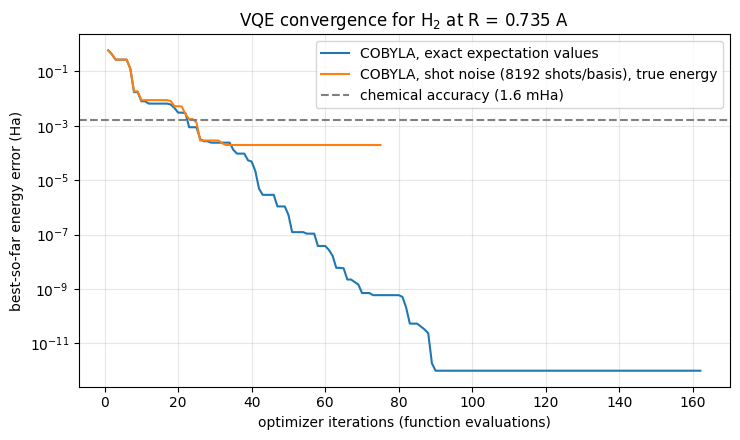

In [8]:
# Energy error vs optimizer iterations (best-so-far)
err_exact = np.minimum.accumulate(hist_exact) - E_el_exact
err_shots = np.minimum.accumulate(true_hist) - E_el_exact
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy(np.arange(1, len(err_exact) + 1), np.maximum(err_exact, 1e-12),
            label="COBYLA, exact expectation values")
ax.semilogy(np.arange(1, len(err_shots) + 1), np.maximum(err_shots, 1e-12),
            label=f"COBYLA, shot noise ({SHOTS} shots/basis), true energy")
ax.axhline(1.6e-3, color="grey", ls="--", label="chemical accuracy (1.6 mHa)")
ax.set_xlabel("optimizer iterations (function evaluations)")
ax.set_ylabel("best-so-far energy error (Ha)")
ax.set_title("VQE convergence for H$_2$ at R = 0.735 A")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [9]:
# Dissociation curve: exact diagonalisation vs VQE (exact estimator, best of 3 random starts)
R_grid = np.round(np.arange(0.3, 2.51, 0.1), 3)
E_exact_curve, E_vqe_curve, vqe_err = [], [], []
for R in R_grid:
    H, Enuc = h2_electronic_pauli(R)
    e_el = np.linalg.eigvalsh(H.to_matrix()).min()
    E_exact_curve.append(e_el + Enuc)
    best = np.inf
    for s in range(3):
        xs = np.random.default_rng(SEED + 100 * s + int(round(R * 100))).uniform(0, 2 * np.pi, N_PARAMS)
        r, _, _ = run_cobyla(lambda t, H=H: energy_exact(t, H), xs, maxiter=400)
        best = min(best, r.fun)
    E_vqe_curve.append(best + Enuc)
    vqe_err.append(best - e_el)
E_exact_curve = np.array(E_exact_curve); E_vqe_curve = np.array(E_vqe_curve); vqe_err = np.array(vqe_err)

from scipy.optimize import minimize_scalar
def E_total_exact(R):
    H, Enuc = h2_electronic_pauli(R)
    return np.linalg.eigvalsh(H.to_matrix()).min() + Enuc
i_min = int(np.argmin(E_exact_curve))
opt = minimize_scalar(E_total_exact, bounds=(R_grid[i_min - 1], R_grid[i_min + 1]), method="bounded",
                      options={"xatol": 1e-6})
R_eq, E_eq = opt.x, opt.fun
print(f"Exact equilibrium bond length (bounded minimisation of the exact curve): {R_eq:.4f} A, "
      f"E = {E_eq:.8f} Ha")
print(f"Max |VQE - exact| over the scan: {np.abs(vqe_err).max():.3e} Ha at R = {R_grid[np.argmax(np.abs(vqe_err))]} A")
for R, e, v in zip(R_grid[::4], E_exact_curve[::4], E_vqe_curve[::4]):
    print(f"  R = {R:.2f} A   exact {e:+.6f} Ha   VQE {v:+.6f} Ha")

Exact equilibrium bond length (bounded minimisation of the exact curve): 0.7349 A, E = -1.13730604 Ha
Max |VQE - exact| over the scan: 7.380e-08 Ha at R = 2.5 A
  R = 0.30 A   exact -0.601804 Ha   VQE -0.601804 Ha
  R = 0.70 A   exact -1.136189 Ha   VQE -1.136189 Ha
  R = 1.10 A   exact -1.079193 Ha   VQE -1.079193 Ha
  R = 1.50 A   exact -0.998149 Ha   VQE -0.998149 Ha
  R = 1.90 A   exact -0.954339 Ha   VQE -0.954339 Ha
  R = 2.30 A   exact -0.938922 Ha   VQE -0.938922 Ha


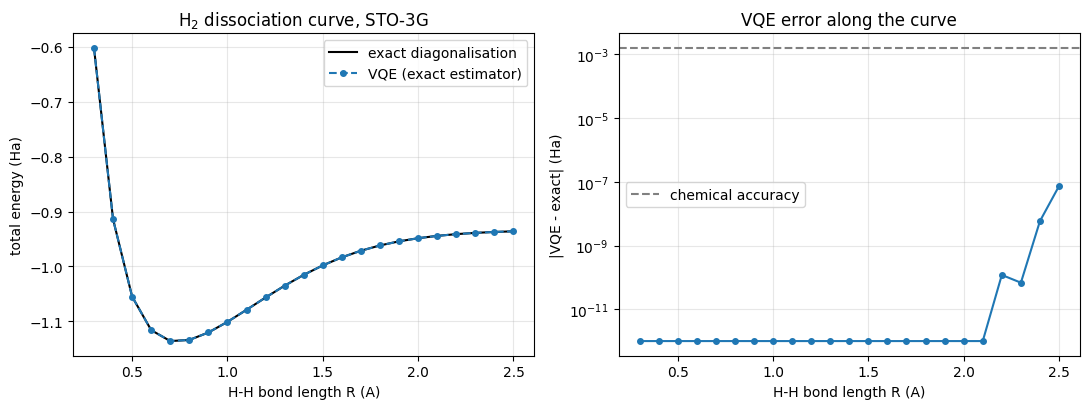

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(R_grid, E_exact_curve, "k-", label="exact diagonalisation")
axes[0].plot(R_grid, E_vqe_curve, "o--", ms=4, label="VQE (exact estimator)")
axes[0].set_xlabel("H-H bond length R (A)"); axes[0].set_ylabel("total energy (Ha)")
axes[0].set_title("H$_2$ dissociation curve, STO-3G"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].semilogy(R_grid, np.maximum(np.abs(vqe_err), 1e-12), "o-", ms=4)
axes[1].axhline(1.6e-3, color="grey", ls="--", label="chemical accuracy")
axes[1].set_xlabel("H-H bond length R (A)"); axes[1].set_ylabel("|VQE - exact| (Ha)")
axes[1].set_title("VQE error along the curve"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [11]:
print("Summary")
print(f"  R = 0.735 A, exact total energy          : {E0_exact:.6f} Ha")
print(f"  R = 0.735 A, VQE exact-estimator error   : {res_exact.fun - E_el_exact:.2e} Ha")
print(f"  R = 0.735 A, VQE shot-noise true error   : {E_true_final_shots - E_el_exact:.2e} Ha")
print(f"  Equilibrium R (exact, bounded minimum)   : {R_eq:.4f} A, E = {E_eq:.6f} Ha")
print(f"  Max VQE error on the 0.3-2.5 A scan     : {np.abs(vqe_err).max():.2e} Ha")

Summary
  R = 0.735 A, exact total energy          : -1.137306 Ha
  R = 0.735 A, VQE exact-estimator error   : -4.44e-16 Ha
  R = 0.735 A, VQE shot-noise true error   : 2.77e-04 Ha
  Equilibrium R (exact, bounded minimum)   : 0.7349 A, E = -1.137306 Ha
  Max VQE error on the 0.3-2.5 A scan     : 7.38e-08 Ha


## Results
Measured in the executed notebook (STO-3G H$_2$, 2 qubits):

* **Hamiltonian check at 0.735 A:** our electronic ground energy is -1.85727502 Ha; the published two-qubit form gives -1.85727503 Ha. The identity term (-1.052373) and the magnitudes of the IZ/ZI (0.397937), ZZ (0.011280) and XX/YY (0.180931) terms agree. Our encoding differs by a single-qubit basis change, so some signs and the XX/YY label differ.
* **Nuclear repulsion at 0.735 A:** 0.7199689944 Ha, giving a total exact ground energy of -1.1373060283 Ha.
* **Exact-expectation COBYLA:** converged in 162 evaluations to an error of 4.4e-16 Ha against exact diagonalisation.
* **Shot-noise COBYLA (8192 shots per measurement basis):** 75 evaluations. The true energy at the returned parameters is off by 2.77e-4 Ha, and the best iterate seen had an error of 1.97e-4 Ha. Both are below chemical accuracy (1.6 mHa). The noisy estimate returned by COBYLA (-1.854094 Ha) is 2.9 mHa above the true value (-1.856998 Ha), which is the shot noise.
* **Dissociation curve (0.3 to 2.5 A, 23 points, best of 3 random starts):** the exact equilibrium bond length is 0.7349 A, with total energy -1.13730604 Ha. The VQE error stays below 7.4e-8 Ha at every point, with the largest error at 2.5 A.
* **Energy at selected bond lengths (total, Ha):** 0.30 A: -0.601804; 0.70 A: -1.136189; 1.10 A: -1.079193; 1.50 A: -0.998149; 1.90 A: -0.954339; 2.30 A: -0.938922 (exact and VQE agree to 6 decimals).

## Conclusions
1. **VQE reproduces the H2 ground state essentially exactly.** At 0.735 A the exact total energy is -1.137306 Ha, and with exact expectation values COBYLA converges to it (error 4e-16 Ha in 162 evaluations). Across the dissociation curve from 0.3 to 2.5 A, the largest deviation from exact diagonalisation is 7.4e-8 Ha, and the equilibrium bond length comes out at 0.7349 A.
2. **Sampling noise is tolerable for this problem.** With 8,192 shots per measurement basis, the true error of the energy at the parameters COBYLA returned is 2.8e-4 Ha, well below chemical accuracy (1.6e-3 Ha), in only 75 evaluations. The noisy estimates themselves fluctuate by about 3e-3 Ha, which is why the notebook reports the true energy at the final parameters.
3. **The Hamiltonian was checked, not assumed.** The electronic energy computed from the STO-3G integrals (-1.85727502 Ha) matches the published two-qubit Hamiltonian (-1.85727503 Ha), and the total energy at 0.7414 A matches a benchmark (-1.1372702 Ha). Our Pauli basis differs from the published one (a YY term instead of XX, some signs flipped) because it is a different single-qubit encoding; the spectrum is identical.
4. **Limits.** H2 in a minimal basis needs only 2 qubits and 1 variational parameter, so this is the easy case: the hard parts of VQE (barren plateaus, deeper ansatze, noisy hardware, larger molecules) do not appear. The coefficients at other bond lengths were computed in the notebook, not taken from a published table. Results are from a noiseless simulator.

**Takeaway for the interview:** VQE is a classical optimiser wrapped around a quantum measurement, and its accuracy is limited by ansatz expressiveness and shot noise; for H2 both are benign, which makes it a clean validation of the pipeline rather than evidence of quantum advantage.